# 03 Random Forest
Bagged decision trees with random feature subsets. Captures non-linear effects (for example the first-year quit spike) and interactions without manual terms. `class_weight` is tuned because quitters are only 16% of rows.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # project root, so `src` is importable

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

from src.modeling import (SEED, get_cv, load_split, linear_features, pruned_linear_features,
                          raw_features, vif, best_cv_scores, cv_summary, finalize, load_scores)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 80)

fs = load_split()
X_train, y_train, X_test, y_test = fs.X_train, fs.y_train, fs.X_test, fs.y_test
cv = get_cv()   # 5-fold x 5 repeats, stratified, same splits in every notebook
print(X_train.shape, X_test.shape, "| train quit rate", round(y_train.mean(), 3))

(1170, 53) (300, 53) | train quit rate 0.158


## 1. Tune with randomized search (all 53 features)
Trees are insensitive to scaling and largely to collinearity, so we start from the full feature set.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score

base = RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=1)
param_dist = {
    "max_depth": [None, 4, 6, 8, 12],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "max_features": ["sqrt", 0.2, 0.33, 0.5],
    "class_weight": [None, "balanced_subsample"],
}
search = RandomizedSearchCV(base, param_dist, n_iter=20, cv=cv, scoring="roc_auc",
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
best_scores = best_cv_scores(search)
print("best params:", search.best_params_)
print(cv_summary(best_scores))

best params: {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': None}
CV AUC 0.7909 +/- 0.0353 (25 folds)


In [3]:
top = (pd.DataFrame(search.cv_results_)
         .sort_values("mean_test_score", ascending=False)
         [["mean_test_score", "std_test_score", "params"]].head(8))
top.round(4)

,mean_test_score,std_test_score,params
18,0.7909,0.0353,"{'min_samples_leaf': 5, 'max_features': 'sqrt'..."
10,0.7901,0.0344,"{'min_samples_leaf': 3, 'max_features': 0.2, '..."
11,0.7894,0.0352,"{'min_samples_leaf': 5, 'max_features': 'sqrt'..."
19,0.7870,0.0343,"{'min_samples_leaf': 10, 'max_features': 0.2, ..."
3,0.7870,0.0365,"{'min_samples_leaf': 10, 'max_features': 0.5, ..."
13,0.7869,0.0341,"{'min_samples_leaf': 10, 'max_features': 0.5, ..."
14,0.7864,0.0373,"{'min_samples_leaf': 3, 'max_features': 0.2, '..."
15,0.7863,0.0344,"{'min_samples_leaf': 5, 'max_features': 0.5, '..."


## 2. Feature selection check
Same tuned hyperparameters, three feature sets. Keep the smaller set unless the bigger one wins by more than the fold-to-fold noise.

In [4]:
from sklearn.base import clone

feature_sets = {
    "all_53": list(X_train.columns),
    "raw_only": raw_features(X_train),
    "pruned_linear": pruned_linear_features(X_train, verbose=False),
}
fs_scores = {k: cross_val_score(clone(search.best_estimator_), X_train[c], y_train, cv=cv,
                                scoring="roc_auc", n_jobs=-1) for k, c in feature_sets.items()}
fs_table = pd.DataFrame({k: [len(feature_sets[k]), v.mean(), v.std()] for k, v in fs_scores.items()},
                        index=["n_features", "cv_auc_mean", "cv_auc_std"]).T
fs_table.round(4)

,n_features,cv_auc_mean,cv_auc_std
all_53,53.0,0.7909,0.0353
raw_only,33.0,0.7970,0.0349
pruned_linear,32.0,0.7972,0.0361


In [5]:
# pick the feature set: best mean, but prefer the smaller set if within 1 SE of the best
se = {k: v.std() / np.sqrt(len(v)) for k, v in fs_scores.items()}
best_key = max(fs_scores, key=lambda k: fs_scores[k].mean())
ok = [k for k in fs_scores if fs_scores[k].mean() >= fs_scores[best_key].mean() - se[best_key]]
chosen = min(ok, key=lambda k: len(feature_sets[k]))
cols = feature_sets[chosen]
final_scores = fs_scores[chosen]
print("chosen feature set:", chosen, f"({len(cols)} features) |", cv_summary(final_scores))

chosen feature set: pruned_linear (32 features) | CV AUC 0.7972 +/- 0.0361 (25 folds)


## 3. Fit final model and inspect importance

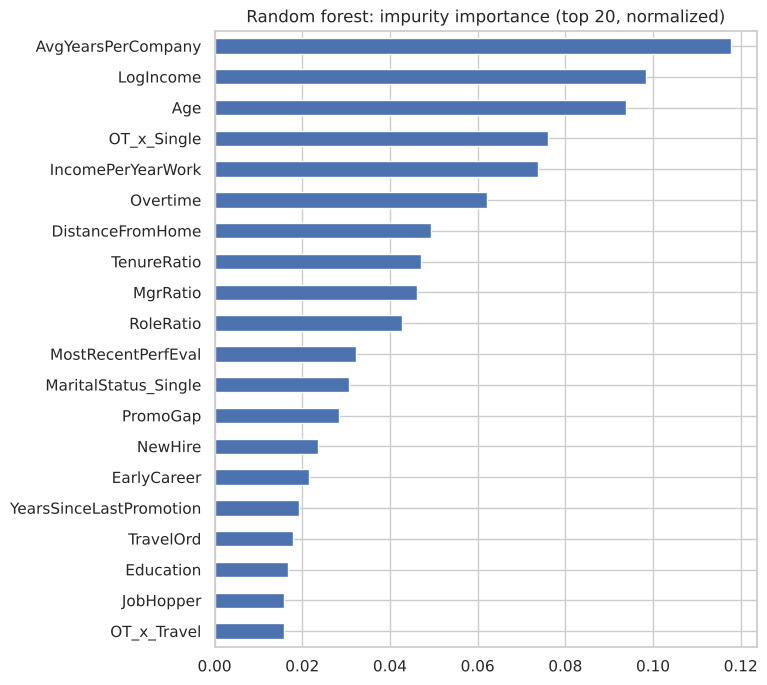

In [6]:
rf = clone(search.best_estimator_).fit(X_train[cols], y_train)
imp = pd.Series(rf.feature_importances_, index=cols).sort_values()
imp = imp / imp.sum()
imp.tail(20).plot.barh(figsize=(7, 8), title="Random forest: impurity importance (top 20, normalized)")
plt.show()

## Test set (scored once)
The model is frozen above. This is the only cell that touches `y_test`. It also saves test predictions and out-of-fold training predictions to `results/preds/` for blending later.

In [7]:
finalize("random_forest", rf, X_train[cols], y_train, X_test[cols], y_test,
         fs.id_train, fs.id_test, final_scores,
         notes=f"features={chosen}; " + ", ".join(f"{k}={v}" for k, v in search.best_params_.items()));

random_forest: CV AUC 0.7972 +/- 0.0361 (25 folds) | TEST AUC 0.7369


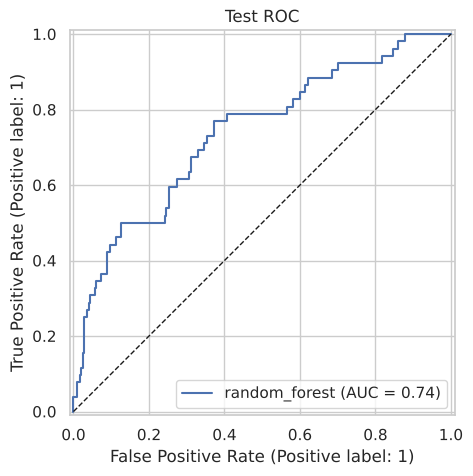

In [8]:
p_test = rf.predict_proba(X_test[cols])[:, 1]
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, p_test, name="random_forest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("Test ROC")
plt.show()

## Leaderboard so far

In [9]:
load_scores()

,model,cv_auc_mean,cv_auc_std,test_auc,n_features,notes
0,logit_elasticnet,0.8182,0.0374,0.7650,47,"C=0.0681, l1_ratio=0.1"
1,logit_l1,0.8165,0.0388,0.7690,47,C=0.316
2,logit_plain_pruned,0.8153,0.0411,0.7760,32,"no penalty, hand + VIF pruned"
3,random_forest,0.7972,0.0361,0.7369,32,"features=pruned_linear; min_samples_leaf=5, ma..."
